# Portfolio sintetico multi-round: local greedy + SCIP

Analisi degli artifact persistiti, senza eseguire la pipeline nel notebook. L'istanza predefinita contiene 30 asset, contro i 5 degli esempi single-pass.

```bash
poetry install --with notebooks,experiments
poetry run python -m qreduce.experiments.portfolio_multi_round --run-id 004_correlation_only --output-root outputs --asset-count 30 --observation-count 300 --graph-edge-mode correlation_only --correlation-threshold 0.90
```

Usare `--asset-count 60` per aumentare ulteriormente la dimensione e un nuovo `--run-id` per ogni pubblicazione. SCIP richiede PySCIPOpt. Il run può terminare con una failure normalizzata se il backend non è disponibile.

**Attenzione:** tre è il numero massimo di round, non quello garantito. La pipeline si arresta già al primo successo o successo parziale; anche un problema grande può quindi produrre un solo round.

In [1]:
from pathlib import Path

from qreduce.experiments import load_experiment_run
from qreduce.experiments.portfolio_multi_round import load_multi_round_correlation_data
from qreduce.notebooks.plots import plot_correlation_matrix
from qreduce.notebooks.presentation import display_records, display_vertical

repository_root = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / "pyproject.toml").is_file()),
    None,
)
if repository_root is None:
    raise RuntimeError("Run this notebook from inside the QReduce repository.")

run_directory = repository_root / "outputs/004_correlation_only"
artifacts = load_experiment_run(run_directory)
if not artifacts.has_reduction:
    raise ValueError("The selected artifact has no reduction rounds.")
result = artifacts.result

## 1. Configurazione, provenance e stato

In [2]:
display_vertical(dict(artifacts.manifest), title="Manifest")
display_vertical(dict(artifacts.config["reduction"]), title="Policy di riduzione")
display_vertical(dict(result["run_result"]), title="Risultato normalizzato")
display_vertical(dict(result["metrics"]), title="Metriche complessive")

Manifest


,campo,valore
0,artifact_schema_version,1.1
1,config_hash,ce052569866d09c7edd02eadd9beabdbb4cf53cc28a23a...
2,created_at,2026-11-13T17:29:48.701433Z
3,experiment_id,synthetic-portfolio-multi-round
4,files,"{\n ""config_used.json"": ""ce052569866d09c7edd0..."
5,fixing_manifest,"{\n ""entries"": [\n {\n ""fixing_origin..."
6,has_reduction,True
7,is_classical_only,False
8,model_export,None
9,policy_provenance,"{\n ""declared_instance_class"": null,\n ""decl..."


Policy di riduzione


,campo,valore
0,candidate_domain_max_items,30
1,candidate_domain_min_items,1
2,max_end_to_end_runtime_seconds,60.0
3,max_recovery_attempts,0
4,max_reduction_rounds,3
5,min_reduction_ratio,0.1
6,num_source_mis_candidates,1
7,recovery_policy_on_domain_too_small,fail
8,recovery_policy_on_infeasible,fail
9,target_binary_variables,0


Risultato normalizzato


,campo,valore
0,adoption_status,adopted
1,classical_solver_status,optimal
2,config_hash,ce052569866d09c7edd02eadd9beabdbb4cf53cc28a23a...
3,diagnostic_message,NaN
4,input_hash,b8229b1651d5bb63c584c53540e8f61c37152bbf471406...
5,policy_hash,NaN
6,postcheck_status,passed
7,round_results,"[\n {\n ""metadata"": {\n ""excluded_cou..."
8,run_id,004_correlation_only
9,run_status,success


Metriche complessive


,campo,valore
0,cumulative_reduction_ratio,0.433333
1,end_to_end_runtime_seconds,0.236595
2,recovery_attempt_count,0.000000
3,round_count,1.000000


## 2. Problema e dimensioni

Le correlazioni e gli archi rappresentano una euristica di riduzione, non vincoli hard del portfolio.

In [3]:
display_vertical({
    "asset_count": len(artifacts.problem["asset_ids"]),
    "original_variable_counts": result["original_variable_counts"],
    "residual_variable_counts": result["residual_variable_counts"],
    "round_count": len(artifacts.round_results),
    "recovery_attempt_count": len(artifacts.recovery_attempts),
}, title="Dimensioni")

Dimensioni


,campo,valore
0,asset_count,30
1,original_variable_counts,"{\n ""binary_free"": 30,\n ""continuous_free"": ..."
2,residual_variable_counts,"{\n ""binary_free"": 17,\n ""continuous_free"": ..."
3,round_count,1
4,recovery_attempt_count,0


## Matrice delle correlazioni degli asset

Le crocette rosse indicano gli archi effettivamente persistiti per il primo round. Se la compilazione non ha prodotto un grafo, la matrice resta visibile senza crocette. Per istanze grandi i valori numerici nelle celle sono omessi per leggibilità.

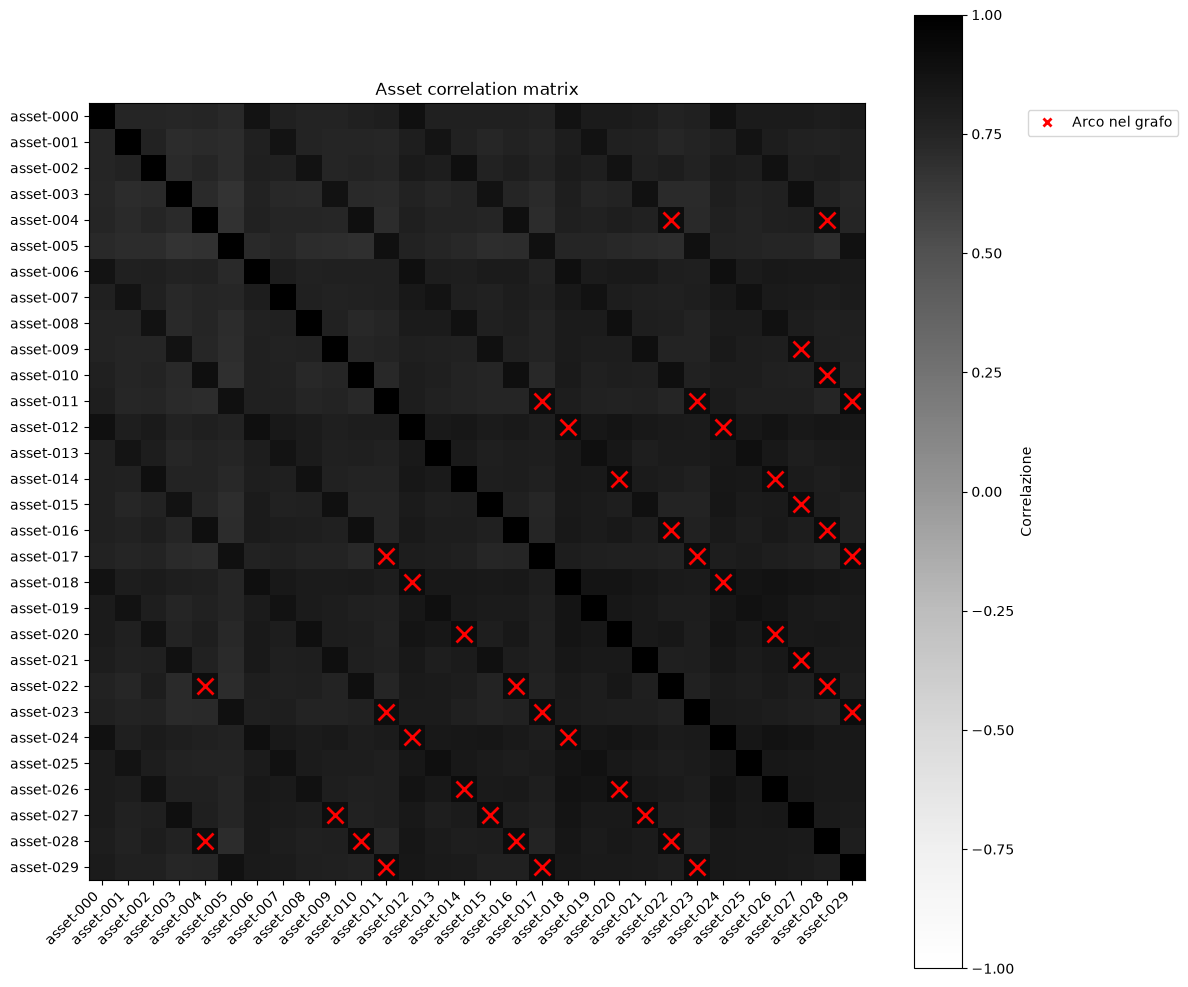

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt

asset_ids, correlation, graph = load_multi_round_correlation_data(run_directory)
fig, ax = plot_correlation_matrix(asset_ids, correlation, graph, threshold=None)
plt.show()

## 3. Risultati per round

Ogni round presenta il proprio stato, la durata, il rapporto di riduzione disponibile, il dominio candidato e gli esiti MIS, solve e post-check. I campi possono essere assenti o nulli in caso di failure.

In [5]:
for index, round_result in enumerate(artifacts.round_results):
    print(f"Round {index}")
    display_vertical({
        "round_index": round_result.get("round_index"),
        "run_status": round_result.get("run_status"),
        "stage": round_result.get("stage"),
        "terminal_reason": round_result.get("terminal_reason"),
        "runtime_seconds": round_result.get("runtime_seconds"),
        "round_reduction_ratio": round_result.get("round_reduction_ratio"),
    }, title="Stato e metriche del round")
    display_vertical({
        "retained_item_ids": round_result.get("retained_item_ids"),
        "fixing_manifest": round_result.get("fixing_manifest"),
        "mis_compilation_result": round_result.get("mis_compilation_result"),
        "mis_execution_result": round_result.get("mis_execution_result"),
        "classical_result": round_result.get("classical_result"),
        "postcheck_result": round_result.get("postcheck_result"),
    }, title="Dettagli del round")

Round 0
Stato e metriche del round


,campo,valore
0,round_index,0
1,run_status,success
2,stage,postcheck
3,terminal_reason,None
4,runtime_seconds,0.236554
5,round_reduction_ratio,None


Dettagli del round


,campo,valore
0,retained_item_ids,"[\n ""asset-024"",\n ""asset-019"",\n ""asset-02..."
1,fixing_manifest,"{\n ""entries"": [\n {\n ""fixing_origin..."
2,mis_compilation_result,"{\n ""compiled_job"": {\n ""backend_family"": ..."
3,mis_execution_result,"{\n ""backend_family"": ""classical_heuristic"",\..."
4,classical_result,"{\n ""best_bound"": -0.10632025000639991,\n ""c..."
5,postcheck_result,"{\n ""failure_reasons"": [],\n ""fixed_variable..."


## 4. Fixing cumulativi, recovery e soluzione

Il dominio mantenuto non coincide necessariamente con la selezione finale. La riduzione euristica non certifica l’ottimo del problema originale.

In [6]:
display_vertical({
    "final_retained_item_ids": result["final_retained_item_ids"],
    "cumulative_fixing_manifest": result["cumulative_fixing_manifest"],
    "classical_result": result["classical_result"],
    "original_problem_optimality_claim": result["original_problem_optimality_claim"],
}, title="Esito finale")
display_records(artifacts.recovery_attempts, record_label="recovery")

Esito finale


,campo,valore
0,final_retained_item_ids,"[\n ""asset-024"",\n ""asset-019"",\n ""asset-02..."
1,cumulative_fixing_manifest,"{\n ""entries"": [\n {\n ""fixing_origin..."
2,classical_result,"{\n ""best_bound"": -0.10632025000639991,\n ""c..."
3,original_problem_optimality_claim,none


,recovery,campo,valore
